In [1]:
import numpy as np
from scipy.spatial import Delaunay
from scipy.spatial import Voronoi, voronoi_plot_2d
import matplotlib.pyplot as plt
import random
import math
#from matplotlib.pyplot import figure

from itertools import count

In [2]:
def uniformpoints(n, m, wiggle=False):
    xy = np.mgrid[-1/(2*n):1+1/(2*n):n*1j, -1/(2*m):1+1/(2*m):m*1j].reshape(2,-1).T
    xy = np.mgrid[0:1:n*1j, 0:1:m*1j].reshape(2,-1).T
    if wiggle:
        xy += np.random.normal(0, 1/(10*n), size=2*n*m).reshape(n*m,2)
    return xy

225  initial points
74  thinned points


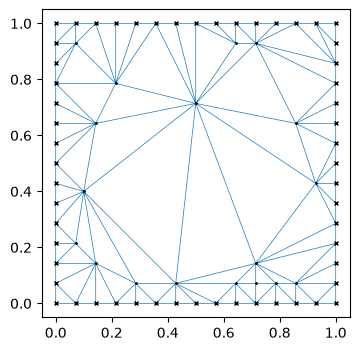

In [11]:
# uniform grid visual

N = 15
eps = 1.0e-10
startpt = [0.1, 0.4]
points = uniformpoints(N, N, wiggle=False)
#points = np.append(points, [startpt], axis=0)
print(len(points), ' initial points')
thinned = [i for i,(x,y) in enumerate(points) if x <= 0.0 or x >= 1.0 or y <= 0.0 or y >= 1.0 or max(abs(x-0.5),abs(y-0.5)) > math.sqrt(random.random())]

# uncomment one of the following for thinned or unthinned
points = np.append(points[thinned],[startpt], axis=0)
#points = np.append(points,[startpt], axis=0)

print(len(points), ' thinned points')

boundarypts = np.array([(x,y) for (x,y) in points if x < eps or x > 1.0-eps or y < eps or y > 1.0-eps])

tri = Delaunay(points)
vor = Voronoi(points)

fig, ax = plt.subplots(figsize=(4, 4))
#plt.figure(figsize=(20,20))
#voronoi_plot_2d(vor, ax=ax)
plt.triplot(points[:,0], points[:,1], tri.simplices, linewidth=0.5)
plt.plot(points[:,0], points[:,1], '.', markersize=2, color='black')
plt.plot(boundarypts[:,0], boundarypts[:,1], 'x', color='black', markersize=3)
plt.gca().set_aspect('equal')
#plt.savefig('del15x15rand.pdf')
plt.show()

In [12]:
len(boundarypts)

56

[0.1 0.4]
56


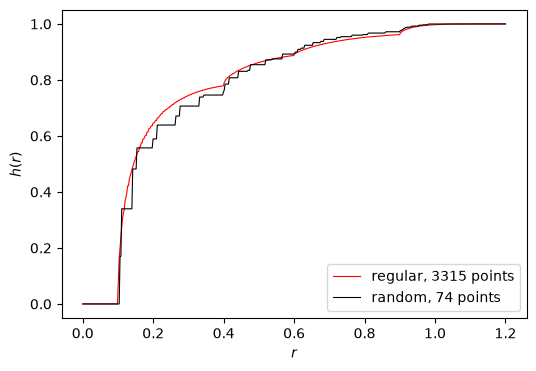

In [13]:
def rownormalize(M):
    "Modifies M so row sums are 1.0"
    norm = np.sum(M, axis=1)
    for i, s in enumerate(norm):
        if s  == 0.0:
            continue
        else:
            M[i] /= s
    #norm[norm == 0.0] = 1.0
    #print('M:')
    #print(M)
    #print('norm:')
    #print(norm)
    #print('M @ the thang!')
    #print(np.diag(1/norm) @ M )
    return M
    return np.diag(1/norm) @ M # very slow; we overwrite M instead

def eudist(a, b):
    return np.linalg.norm(points[a] - points[b])
def dualdist(c, d):
    return np.linalg.norm(vor.vertices[c]- vor.vertices[d])

def closestidx(pt, idxlist):
    bestdist = 9999999
    bestidx = 0
    for j in idxlist:
        d = np.sqrt((pt[0] - points[j][0])**2 + (pt[1] - points[j][1])**2)
        if d < bestdist:
            bestdist = d
            bestidx = j
    return bestidx

#boundary = set(tri.convex_hull.flatten())
boundary = [i for i, (x,y) in enumerate(points) if x <= 0.0 or x >= 1.0 or y <= 0.0 or y >= 1.0]
boundary_l = sorted(list(boundary))
interior = [i for i in range(len(points)) if i not in boundary]
#print(boundary)
#print(interior)

u = len(boundary)
v = len(interior)
w = len(points)
#R = np.zeros((v, u))
#Q = np.zeros((v, v))
W = np.zeros((w, w))

for spts, vpts in zip(vor.ridge_points, vor.ridge_vertices):
    a, b = spts
    c, d = vpts
#    print(a,b)
#    print(d,c)
    if a in boundary and b in boundary:
        continue
    if a not in boundary: # b is interior, a in boundary
        W[a, b] = dualdist(c, d) / eudist(b, a)
    if b not in boundary:
        W[b, a] = dualdist(c, d) / eudist(b, a)

# row normalize W
nW = rownormalize(W)

# Compute the exit probabilities

Q = nW[np.ix_(interior,interior)]
R = nW[np.ix_(interior, boundary_l)]
B = np.linalg.solve(np.eye(v)-Q, R)


RADIUS = 0.6

ix = [x for (x,y) in points[interior]]
iy = [y for (x,y) in points[interior]]
bx = [x for (x,y) in points[boundary_l]]
by = [y for (x,y) in points[boundary_l]]
intidx = dict(zip(interior, count()))
bdyidx = dict(zip(boundary, count()))

baseidx = closestidx(startpt, interior)
basept = points[baseidx]
print(basept)
dists = np.sqrt((np.array(bx) - basept[0]) ** 2 + (np.array(by) - basept[1])**2)
print(len(dists))

#baseidx = intidx[basept]

r = np.linspace(0,2*RADIUS,500)
harm = r*0
for i in range(len(r)):
    harm[i] = np.dot(B[interior.index(baseidx)], dists < r[i])


fig, ax = plt.subplots(figsize=(6, 4))
#plt.plot(r,harm50_50, color='red', label='50x50 base=0.11, 0.39')
#plt.plot(r,harm150_150, color='black', label='150x150 base=0.1033, 0.3967')
try:
    plt.plot(r,harm150x150, color='red', lw=0.8, label=f'regular, {3315} points')
except NameError:
    print("harm15x150 undefined")
plt.plot(r, harm, color='black', lw=0.8, label=f'random, {len(points)} points')
plt.legend(loc='lower right')
plt.xlabel('$r$')
plt.ylabel('$h(r)$')
plt.show()
#plt.savefig('hfunc150_150v329.pdf')

In [10]:
# Run for uniform 150x150 (unthinned) to use as a baseline, save for later plots
harm150x150=harm

### Experimenting with various alternate strategies below

In [ ]:
N = 500

startpt = [0.1, 0.4]

#points = np.random.uniform(size=2*N).reshape((N,2))
#points = np.array([[0, 0], [0, 1.1], [1, 0], [1, 1], [0.4,0.6], [0.6,0.4]])
#points = uniformpoints(50, 50, wiggle=True)
points = np.random.uniform(0.0, 1.0, size=(5*N,2))
points[0:N,0] = 0.0
points[N:2*N,0] = 1.0
points[2*N:3*N,1] = 0.0
points[3*N:4*N,1] = 1.0
points[0] = startpt
#print('points', points)
thinned = [i for i,(x,y) in enumerate(points) if x <= 0.0 or x >= 1.0 or y <= 0.0 or y >= 1.0 or max(abs(x-0.5),abs(y-0.5)) > math.sqrt(random.random())]
#print('thinned', thinned)
#points = np.append(points[thinned],[startpt], axis=0)
print(points)
tri = Delaunay(points)
vor = Voronoi(points)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 12))
#plt.figure(figsize=(20,20))
voronoi_plot_2d(vor, ax=ax)
plt.triplot(points[:,0], points[:,1], tri.simplices, linewidth=0.5)
plt.plot(points[:,0], points[:,1], 'o', markersize=1)
plt.gca().set_aspect('equal')
#plt.savefig('del50_50.png')
plt.show()

In [ ]:
def rownormalize(M):
    norm = np.sum(M, axis=1)
    for i, s in enumerate(norm):
        if s  == 0.0:
            continue
        else:
            M[i] /= s
    #norm[norm == 0.0] = 1.0
    #print('M:')
    #print(M)
    #print('norm:')
    #print(norm)
    #print('M @ the thang!')
    #print(np.diag(1/norm) @ M )
    return M
    return np.diag(1/norm) @ M # very slow; we overwrite M instead

def eudist(a, b):
    return np.linalg.norm(points[a] - points[b])
def dualdist(c, d):
    return np.linalg.norm(vor.vertices[c]- vor.vertices[d])


boundary = set(tri.convex_hull.flatten())
boundary = [i for i, (x,y) in enumerate(points) if x <= 0.0 or x >= 1.0 or y <= 0.0 or y >= 1.0]
boundary_l = sorted(list(boundary))
interior = [i for i in range(len(points)) if i not in boundary]
#print(boundary)
#print(interior)

u = len(boundary)
v = len(interior)
w = len(points)
#R = np.zeros((v, u))
#Q = np.zeros((v, v))
W = np.zeros((w, w))

for spts, vpts in zip(vor.ridge_points, vor.ridge_vertices):
    a, b = spts
    c, d = vpts
#    print(a,b)
#    print(d,c)
    if a in boundary and b in boundary:
        continue
    if a not in boundary: # b is interior, a in boundary
        W[a, b] = dualdist(c, d) / eudist(b, a)
    if b not in boundary:
        W[b, a] = dualdist(c, d) / eudist(b, a)
        
#print(W)

In [ ]:
bdypoints = points[boundary]
fig, ax = plt.subplots(figsize=(12, 12))
#plt.figure(figsize=(20,20))
#voronoi_plot_2d(vor, ax=ax)
plt.triplot(points[:,0], points[:,1], tri.simplices, linewidth=0.5)
plt.plot(points[:,0], points[:,1], 'o', markersize=1)
plt.plot(bdypoints[:,0], bdypoints[:,1], 'x', markersize=5)
plt.gca().set_aspect('equal')
#plt.savefig('del50_50.png')
plt.show()

In [ ]:
%%time

nW = rownormalize(W)

In [ ]:
%%time
# Compute the exit probabilities

Q = nW[np.ix_(interior,interior)]
R = nW[np.ix_(interior, boundary_l)]
B = np.linalg.solve(np.eye(v)-Q, R)

In [ ]:
RADIUS = 0.6

ix = [x for (x,y) in points[interior]]
iy = [y for (x,y) in points[interior]]
bx = [x for (x,y) in points[boundary_l]]
by = [y for (x,y) in points[boundary_l]]
intidx = dict(zip(interior, count()))
bdyidx = dict(zip(boundary, count()))

baseidx = closestidx(startpt, interior)
basept = points[baseidx]
print(basept)
dists = np.sqrt((np.array(bx) - basept[0]) ** 2 + (np.array(by) - basept[1])**2)
print(len(dists))

#baseidx = intidx[basept]

r = np.linspace(0,2*RADIUS,500)
harm = r*0
for i in range(len(r)):
    harm[i] = np.dot(B[interior.index(baseidx)], dists < r[i])

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))
#plt.plot(r,harm50_50, color='red', label='50x50 base=0.11, 0.39')
#plt.plot(r,harm150_150, color='black', label='150x150 base=0.1033, 0.3967')
plt.plot(r, harm, color='green', label=f'{N} points, base={basept}')
plt.legend(loc='lower right')
plt.xlabel('$r$')
plt.ylabel('$h(r)$')
#plt.plot(r,harm150_50, color='green')
#plt.savefig('hfunc150_150v.png')